In [1]:
!pip install torch-levenberg-marquardt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.4/825.4 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 96.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 58.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 963.5/963.5 kB 42.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-

In [2]:
path = "/content/N2.csv"

In [ ]:
# Load your data
df = pd.read_csv(path)
T = df["T"].values
Cp = df["Cp"].values


# shulman :

/tmp/ipython-input-3-244725865.py:25: OptimizeWarning: Covariance of the parameters could not be estimated
  params, _ = curve_fit(shulman, T, Cp)


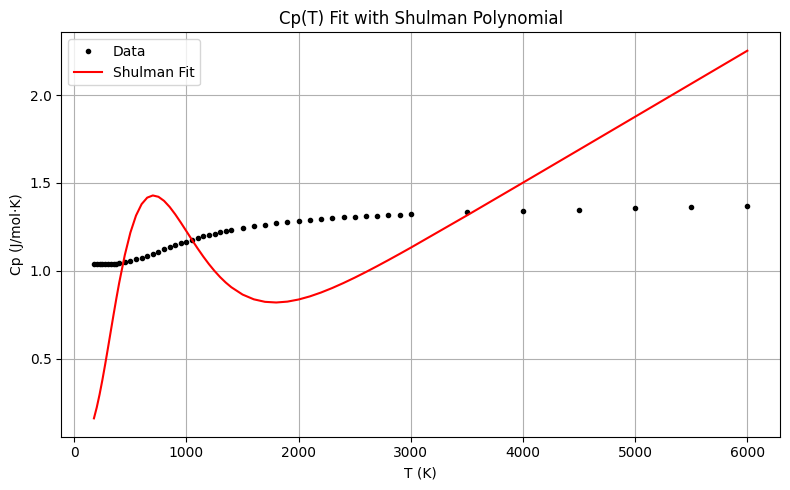

Fitted Coefficients: [3.75334679e-04 1.00000000e+00 5.44689959e-01 6.84483921e-11
 1.00000000e+00 1.00000000e+00]


In [3]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt


R = 8.314

def shulman(T, a, b, c, d, e, f):
    T = np.clip(T, 1e-6, None)
    term1 = a * T
    term2 = 1 - np.exp(-b * T**2)
    term3 = 1.0
    term6 = np.exp(-c * np.sqrt(T))
    term4 = d * T**6
    term5 = e * T**4 * np.exp(-f * T)
    return term1 * term2 * (term3 + term6 * term4 + term5)

# Fit
params, _ = curve_fit(shulman, T, Cp)
Cp_fit = shulman(T, *params)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(T, Cp, "k.", label="Data")
plt.plot(T, Cp_fit, "r-", label="Shulman Fit")
plt.xlabel("T (K)")
plt.ylabel("Cp (J/mol·K)")
plt.title("Cp(T) Fit with Shulman Polynomial")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

print("Fitted Coefficients:", params)


# nasa polynomial form for gaz :

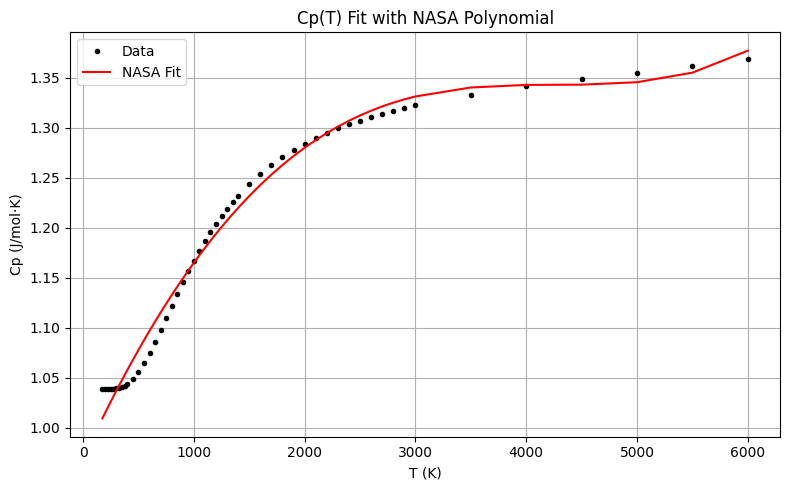

Fitted Coefficients: [ 1.16477380e-01  2.90012473e-05 -5.54836399e-09  1.42175133e-13
  3.41082731e-17]


In [4]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt


T = df["T"].values
Cp = df["Cp"].values

R = 8.314

# Define NASA polynomial model
def nasa_cp(T, a1, a2, a3, a4, a5):
    return R * (a1 + a2*T + a3*T**2 + a4*T**3 + a5*T**4)

# Fit
params, _ = curve_fit(nasa_cp, T, Cp)
Cp_fit = nasa_cp(T, *params)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(T, Cp, "k.", label="Data")
plt.plot(T, Cp_fit, "r-", label="NASA Fit")
plt.xlabel("T (K)")
plt.ylabel("Cp (J/mol·K)")
plt.title("Cp(T) Fit with NASA Polynomial")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

print("Fitted Coefficients:", params)


# pinns :

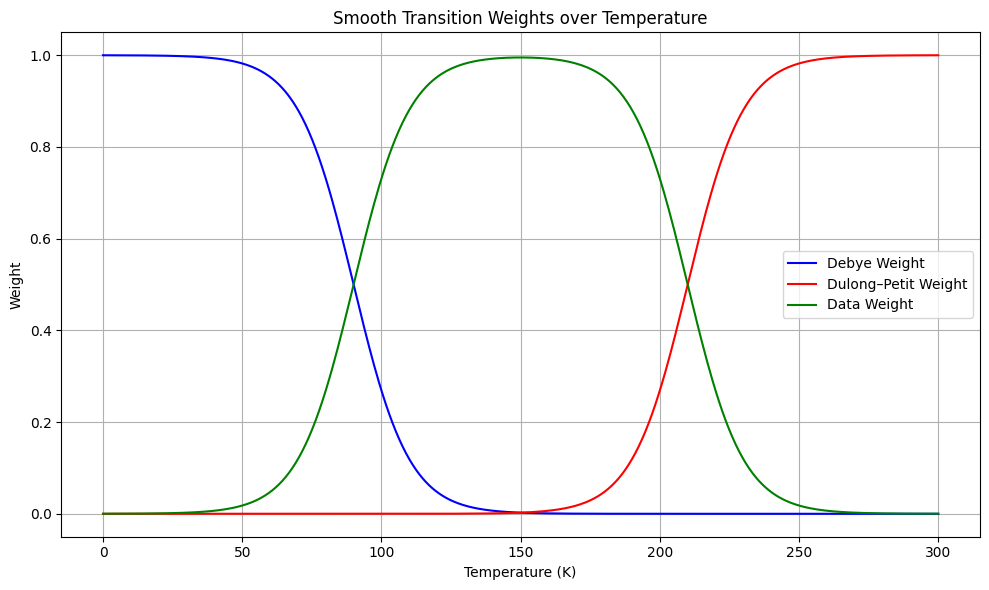

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Parameters
T = np.linspace(0, 300, 500)
T_low = 80
T_high = 220
m = 10
s = 10

# Compute weights
w_debye = 1 - sigmoid((T - (T_low + m)) / s)
w_dp = sigmoid((T - (T_high - m)) / s)
w_data = 1 - w_debye - w_dp
w_data = np.clip(w_data, 0, 1)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(T, w_debye, label='Debye Weight', color='blue')
plt.plot(T, w_dp, label='Dulong–Petit Weight', color='red')
plt.plot(T, w_data, label='Data Weight', color='green')

plt.xlabel('Temperature (K)')
plt.ylabel('Weight')
plt.title('Smooth Transition Weights over Temperature')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Epoch 0, Loss: 1.341865
Epoch 500, Loss: 0.109462
Epoch 1000, Loss: 0.101243
Epoch 1500, Loss: 0.100310
Epoch 2000, Loss: 0.100288
Epoch 2500, Loss: 0.100284
Epoch 3000, Loss: 0.100283
Epoch 3500, Loss: 0.100283
Epoch 4000, Loss: 0.100283
Epoch 4500, Loss: 0.100283


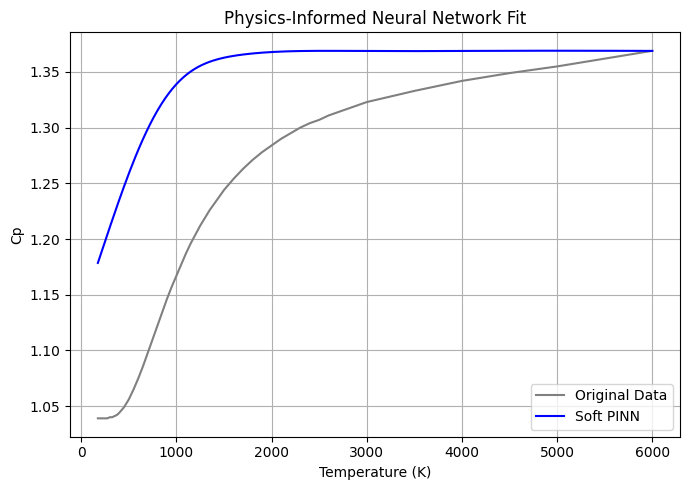

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------
# 1. Load Data
# ------------------------------------
df = pd.read_csv(path)  # replace with your file
T_np = df.iloc[:, 0].values
Cp_np = df.iloc[:, 1].values

# Normalize T and Cp
T_min, T_max = T_np.min(), T_np.max()
Cp_min, Cp_max = Cp_np.min(), Cp_np.max()

def normalize(x, x_min, x_max):
    return (x - x_min) / (x_max - x_min)

def denormalize(x_norm, x_min, x_max):
    return x_norm * (x_max - x_min) + x_min

T_norm = normalize(T_np, T_min, T_max)
Cp_norm = normalize(Cp_np, Cp_min, Cp_max)

T_tensor = torch.tensor(T_norm, dtype=torch.float32).unsqueeze(1)
Cp_tensor = torch.tensor(Cp_norm, dtype=torch.float32).unsqueeze(1)

# ------------------------------------
# 2. Neural Network
# ------------------------------------
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.hidden(x)

model2 = Net()

# ------------------------------------
# 3. Custom Physics Loss
# ------------------------------------
def soft_mask(T, T_center, width):
    return torch.sigmoid((T - T_center) / width)

def physics_loss(T, Cp_pred, Cp_true, m=0.1, s=0.1):
    # Debye: T^3
    Cp_debye = T**3
    Cp_dp = torch.ones_like(T)  # Constant Dulong–Petit (normalized to 1)

    # Losses
    loss_data = (Cp_pred - Cp_true)**2
    loss_debye = (Cp_pred - Cp_debye / Cp_debye.max())**2
    loss_dp = (Cp_pred - Cp_dp)**2

    # Weights
    T_low = normalize(50,T_min, T_max) # ~low T region
    T_high = normalize(500,T_min, T_max ) # ~high T region
    w_debye = 1 - soft_mask(T, T_low + m, s)
    w_dp = soft_mask(T, T_high - m, s)
    w_data = 1.0 - w_debye - w_dp
    w_data = w_data.clamp(0.0, 1.0)

    # Final loss
    total_loss = w_data * loss_data + w_debye * loss_debye + w_dp * loss_dp
    return total_loss.mean()

# ------------------------------------
# 4. Train the model
# ------------------------------------
optimizer = torch.optim.Adam(model2.parameters(), lr=1e-3)
epochs = 5000
loss_history = []

for epoch in range(epochs):
    model2.train()
    optimizer.zero_grad()
    Cp_pred = model2(T_tensor)

    loss = physics_loss(T_tensor, Cp_pred, Cp_tensor, m=0.05, s=0.05)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")

# ------------------------------------
# 5. Plot Results
# ------------------------------------
model2.eval()
T_test = torch.linspace(0, 1, 300).unsqueeze(1)
Cp_test_pred = model2(T_test).detach().numpy()

# Denormalize
T_test_real = denormalize(T_test.numpy(), T_min, T_max)
Cp_test_real = denormalize(Cp_test_pred, Cp_min, Cp_max)

plt.figure(figsize=(7, 5))
plt.plot(T_np, Cp_np, label="Original Data", color="gray")
plt.plot(T_test_real, Cp_test_real, label="Soft PINN", color="blue")
plt.xlabel("Temperature (K)")
plt.ylabel("Cp")
plt.title("Physics-Informed Neural Network Fit")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


In [9]:
# Convert your original T to tensor and normalize
T_tensor_true = torch.tensor(normalize(T_np, T_min, T_max), dtype=torch.float32).unsqueeze(1)

# Predict using the trained model
model2.eval()
with torch.no_grad():

    Cp_pred_norm = model2(T_tensor_true).squeeze().numpy()

# Denormalize the Cp prediction
y_pred3 = denormalize(Cp_pred_norm, Cp_min, Cp_max)


# comparaison :

In [10]:
def Cp_shulman(T , a=7.73e-3 , b=1.263e-3 ,c=3 ,d=8.47e-3 , e=2.0825e-7 ,f=4.97e-2 ):
    T = np.clip(T, 1e-6, None)
    term1 = a * T
    term2 = 1 - np.exp(-b * T**2)
    term3 = 1
    term6 = np.exp(-c * np.sqrt(T))
    term4 = d * (T**6)
    term5 = e * T**4 * np.exp(- f* T)
    return term1 * term2 * (term3 + term6 * term4 + term5)



In [11]:
a = 3.75334679e-04
b = 1.00000000e+00
c = 5.44689959e-01
d = 6.84483921e-11
e = 1.00000000e+00
f = 1.00000000e+00


               Model       MSE       MAE         R²
0            Shulman  0.157623  0.338244 -11.313543
1      NASA equation  0.000138  0.009742   0.989188
2  Soft PINNs + PySR  0.019408  0.124660  -0.516135


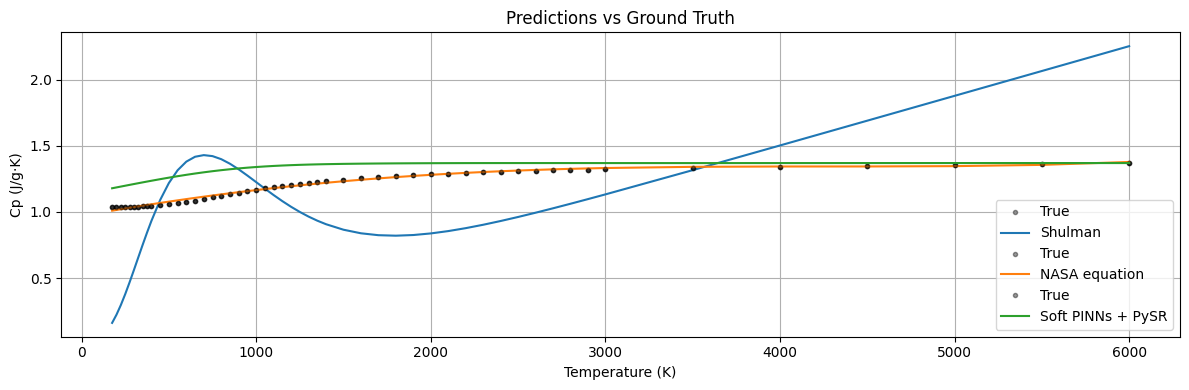

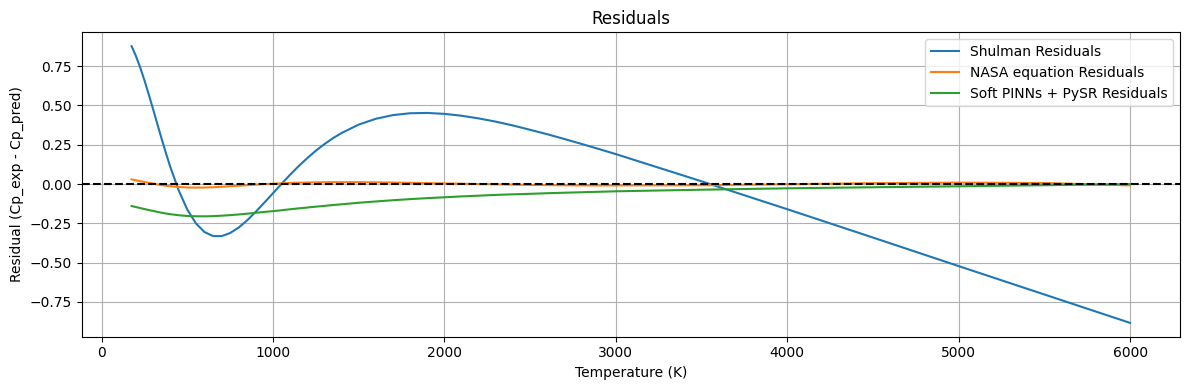

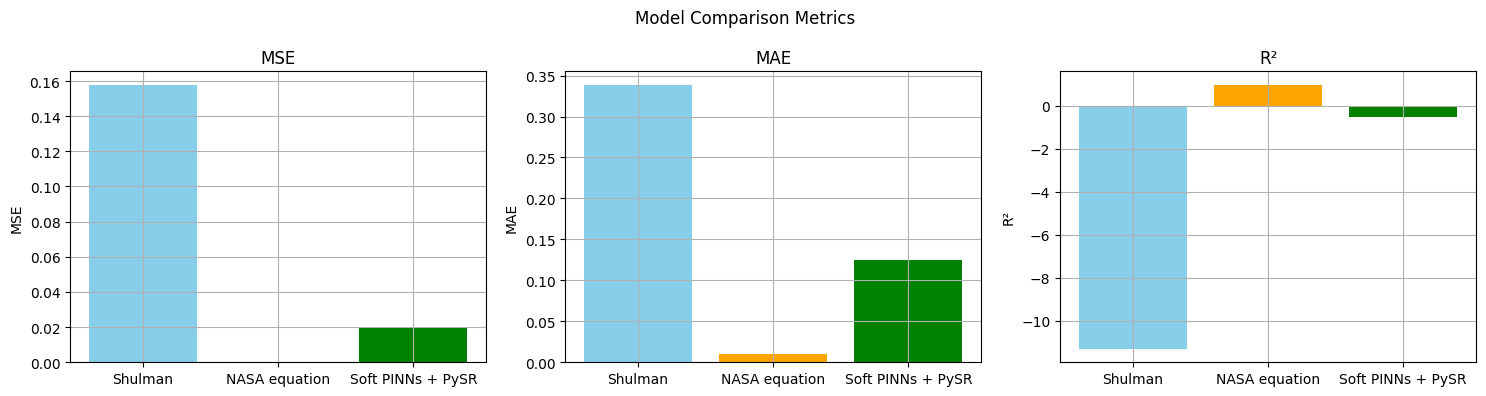

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pandas as pd
import torch

# ------------------------
# Load data
# ------------------------
df = pd.read_csv(path)
T = df["T"].values            # Temperature values (length N)
Cp_exp = df["Cp"].values      # Experimental Cp values (length N)
T_tensor = torch.tensor(T, dtype=torch.float32).view(-1, 1)


# Predictions
y_pred1 = Cp_shulman(T, a, b, c, d, e, f)  # ➜ shape (93,)
y_pred2 = nasa_cp( T, 1.16477380e-01 , 2.90012473e-05 ,-5.54836399e-09 , 1.42175133e-13,3.41082731e-17)


# ------------------------
# Model comparison
# ------------------------
model_names = ['Shulman', 'NASA equation', 'Soft PINNs + PySR']
predictions = [y_pred1, y_pred2, y_pred3]

results = []
for name, pred in zip(model_names, predictions):
    Cp_exp_adj = Cp_exp[:len(pred)]
    mse = mean_squared_error(Cp_exp_adj, pred)
    mae = mean_absolute_error(Cp_exp_adj, pred)
    r2 = r2_score(Cp_exp_adj, pred)
    results.append((name, mse, mae, r2))

df_metrics = pd.DataFrame(results, columns=["Model", "MSE", "MAE", "R²"])
print(df_metrics)

# ------------------------
# Plot Predictions
# ------------------------
plt.figure(figsize=(12, 4))
for name, pred in zip(model_names, predictions):
    T_plot = T[:len(pred)]
    Cp_plot = Cp_exp[:len(pred)]
    plt.plot(T_plot, Cp_plot, "k.", label="True", alpha=0.4)
    plt.plot(T_plot, pred, label=name)
plt.xlabel("Temperature (K)")
plt.ylabel("Cp (J/g·K)")
plt.title("Predictions vs Ground Truth")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# ------------------------
# Plot Residuals
# ------------------------
plt.figure(figsize=(12, 4))
for name, pred in zip(model_names, predictions):
    T_plot = T[:len(pred)]
    Cp_adj = Cp_exp[:len(pred)]
    residuals = Cp_adj - pred
    plt.plot(T_plot, residuals, label=f"{name} Residuals")
plt.axhline(0, color='black', linestyle='--')
plt.title("Residuals")
plt.xlabel("Temperature (K)")
plt.ylabel("Residual (Cp_exp - Cp_pred)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# ------------------------
# Plot Metrics Bar Chart
# ------------------------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, metric in enumerate(['MSE', 'MAE', 'R²']):
    ax[i].bar(df_metrics["Model"], df_metrics[metric], color=['skyblue', 'orange', 'green'])
    ax[i].set_title(metric)
    ax[i].set_ylabel(metric)
    ax[i].grid(True)
plt.suptitle("Model Comparison Metrics")
plt.tight_layout()
plt.show()
